# Turbulent channel flow: k-omega SST against DNS

A fully developed channel at Re_tau = 392 is modelled as a periodic slab (4 cells in x) driven by
a constant pressure gradient. With u_tau = 1 and the half-height 1, the wall shear stress must
be exactly 1 at equilibrium, and U is directly U+. The reference is the DNS of Moser, Kim &
Mansour (1999).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from flowtrace.validation.turbulent import run_channel, DNS_YPLUS, DNS_UPLUS, RE_TAU

sst = run_channel("k-omega-sst")
ke = run_channel("k-epsilon-standard")
for r in (sst, ke):
    print(f"{r['model']:<20} iterations {r['iterations']:>5}  wall shear {r['tau_w']:.4f}  "
          f"first-cell y+ {r['y_plus_first']:.2f}  max |U+ - DNS| {r['max_abs_err_pct']:.1f} % (y+ >= {r['compared_from_yplus']:.0f})")

k-omega-sst          iterations  3226  wall shear 0.9994  first-cell y+ 0.25  max |U+ - DNS| 4.1 % (y+ >= 1)
k-epsilon-standard   iterations  5110  wall shear 0.9999  first-cell y+ 24.31  max |U+ - DNS| 3.5 % (y+ >= 51)


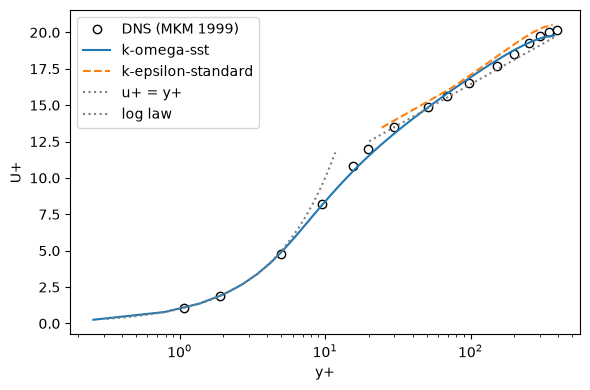

In [2]:
yp = np.logspace(-0.5, np.log10(RE_TAU), 200)
fig, ax = plt.subplots(figsize=(6, 4))
ax.semilogx(DNS_YPLUS, DNS_UPLUS, "ko", mfc="none", label="DNS (MKM 1999)")
for r, st in ((sst, "-"), (ke, "--")):
    ax.semilogx(np.array(r["profile_y"]) * RE_TAU, r["profile_u"], st, label=r["model"])
ax.semilogx(yp[yp < 12], yp[yp < 12], ":", color="gray", label="u+ = y+")
ax.semilogx(yp[yp > 20], np.log(yp[yp > 20]) / 0.41 + 5.2, ":", color="gray", label="log law")
ax.set_xlabel("y+"); ax.set_ylabel("U+"); ax.legend(); fig.tight_layout()

SST resolves the viscous sublayer (first cell at y+ ~ 0.25). The k-epsilon run uses scalable
wall functions with the first cell at y+ ~ 25, so it is only compared from y+ = 30 outwards.